Xander Lee\
GitHub: xylee2\
USC ID: 2501701937\
DSCI 552\
30 October, 2026

## Homework 5

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import tree
from skmultilearn.problem_transform import LabelPowerset
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
import warnings

from sklearn.impute import KNNImputer
import seaborn as sns

from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

from xgboost import XGBRegressor

**1) Decision Trees as Interpretable Models**

**a)** Download the [Accute Inflamations](https://archive.ics.uci.edu/ml/datasets/Acute+Inflammations) data.

In [3]:
path = "../data/diagnosis.csv"
cols = ["temp",
        "nausea",
        "lumbarpain",
        "urinepushing",
        "micturitionpushing",
        "burning",
        "inflammation",
        "nephritis"]

# UTF-16 required (fixes 2 bytes per character)
acute = pd.read_csv(path, sep='\t', names=cols, encoding="utf-16", decimal=",")

**b)** Build a decision tree on the whole data set and plot it. This data set is a multi-label data set. `sklearn` seems to support building multi-label decision trees. Alternatively, you can use the label powerset method to convert it to a multiclass data set. Also, you can use the binary relevance method and build one decision tree for each label. It seems that the label powerset approach is more relevant here. Is that right?

Yes, the label powerset approach is more relevant if there is information stored in the combination of outputs/classes (in this case, label powerset captures inflammation and nephritis dependencies exactly). However, this can break down when there are too few examples per class. We see that there are at least 19 examples per class below:

In [4]:
# Prevents warning from replace
pd.set_option('future.no_silent_downcasting', True)

# Convert all columns to floats
X = acute.drop(columns=["inflammation","nephritis"])
X = X.replace({"yes":1,"no":0}).astype(float)
y = acute[["inflammation","nephritis"]]
y = y.replace({"yes":1,"no":0}).astype(float)

# Fit label powerset classifier
classifier = LabelPowerset(tree.DecisionTreeClassifier(random_state=42))
classifier.fit(X,y)

# Determine number of data points per class
ys = classifier.transform(y)
unique, counts = np.unique(ys, return_counts=True)
print(np.asarray((unique,counts)))

[[ 0  1  2  3]
 [30 40 31 19]]


The label powerset turns each combination of the two diagnoses into one class:

| Class | Inflammation of urinary bladder | Nephritis of renal pelvis | Meaning | Patients |
|:---:|:---:|:---:|---|:---:|
| 0 | no | no | Neither condition | 30 |
| 1 | yes | no | Inflammation only | 40 |
| 2 | no | yes | Nephritis only | 31 |
| 3 | yes | yes | Both conditions | 19 |

In total, 59 patients have inflammation (40 + 19) and 50 have nephritis (31 + 19). The four entries of `value` in each node of the tree below follow the same class order.

In [5]:
feature_names = X.columns

# Plotted with browser Graphviz
dotfile = open("dtfull.dot", 'w')
tree.export_graphviz(classifier.classifier, out_file=dotfile, feature_names=feature_names)
dotfile.close()

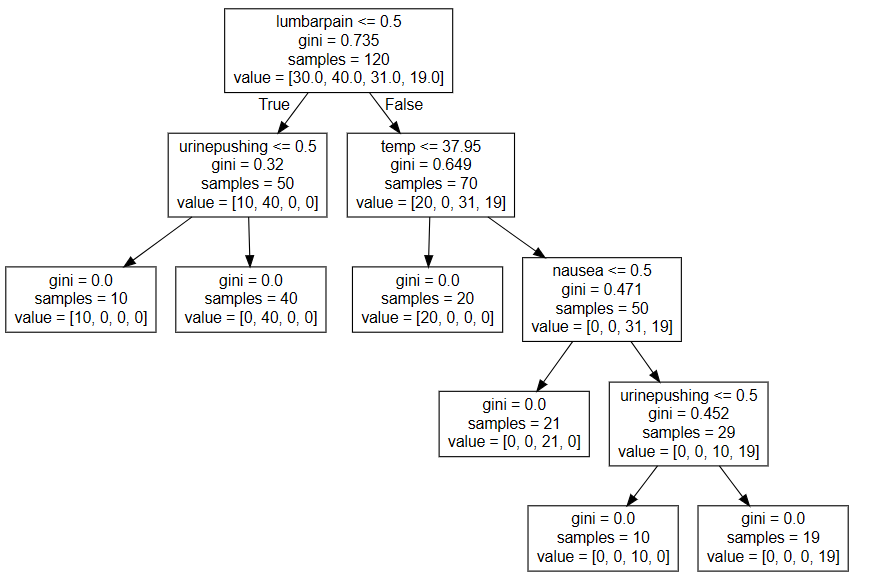

**c)** Convert the decision rules into a set of IF-THEN rules. You can use the code [here](https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html).

In [6]:
def tree_to_pseudo(tree, feature_names):
	"""
	Outputs a decision tree model as if/then pseudocode
	
	Parameters:
	-----------
	tree: decision tree model
		The decision tree to represent as pseudocode
	feature_names: list
		The feature names of the dataset used for building the decision tree
	"""

	left = tree.tree_.children_left
	right = tree.tree_.children_right
	threshold = tree.tree_.threshold
	features = [feature_names[i] for i in tree.tree_.feature]
	value = tree.tree_.value

	def recurse(left, right, threshold, features, node, depth=0):
		indent = "  " * depth
		if (threshold[node] != -2):
			print(indent,"if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
			if left[node] != -1:
				recurse (left, right, threshold, features, left[node], depth+1)
				print(indent,"} else {")
				if right[node] != -1:
					recurse (left, right, threshold, features, right[node], depth+1)
				print(indent,"}")
		else:
			print(indent,"return " + str(value[node]))

	recurse(left, right, threshold, features, 0)


In [7]:
tree_to_pseudo(classifier.classifier,feature_names)

 if ( lumbarpain <= 0.5 ) {
   if ( urinepushing <= 0.5 ) {
     return [[1. 0. 0. 0.]]
   } else {
     return [[0. 1. 0. 0.]]
   }
 } else {
   if ( temp <= 37.95000076293945 ) {
     return [[1. 0. 0. 0.]]
   } else {
     if ( nausea <= 0.5 ) {
       return [[0. 0. 1. 0.]]
     } else {
       if ( urinepushing <= 0.5 ) {
         return [[0. 0. 1. 0.]]
       } else {
         return [[0. 0. 0. 1.]]
       }
     }
   }
 }


Written out in plain terms (patient counts per rule from the tree in part b):

1. **IF** no lumbar pain **AND** no urine pushing **THEN** neither condition *(10 patients)*
2. **IF** no lumbar pain **AND** urine pushing **THEN** inflammation of the urinary bladder only *(40 patients)*
3. **IF** lumbar pain **AND** temperature ≤ 37.95°C **THEN** neither condition *(20 patients)*
4. **IF** lumbar pain **AND** temperature > 37.95°C **AND** no nausea **THEN** nephritis of renal pelvis origin only *(21 patients)*
5. **IF** lumbar pain **AND** temperature > 37.95°C **AND** nausea **AND** no urine pushing **THEN** nephritis of renal pelvis origin only *(10 patients)*
6. **IF** lumbar pain **AND** temperature > 37.95°C **AND** nausea **AND** urine pushing **THEN** both conditions *(19 patients)*

***

**d)** Use cost-complexity pruning to find a minimal decision tree and a set of decision rules with high interpretability.

In [8]:
warnings.filterwarnings("ignore", message="X has feature names")

# Full tree and pruning path
full = LabelPowerset(tree.DecisionTreeClassifier(random_state=42))
full.fit(X, y)
y_lp = full.transform(y)    # Gives same IDs LabelPowerset assigns
ccp_alphas = full.classifier.cost_complexity_pruning_path(X, y_lp).ccp_alphas

# Cross-validate one pruned tree per alpha (10-fold)
cv = KFold(10,shuffle=True,random_state=42)
rows = []
for alpha in ccp_alphas:
    m = LabelPowerset(tree.DecisionTreeClassifier(random_state=42, ccp_alpha=alpha))
    scores = cross_val_score(m, X, y, cv=cv)
    m.fit(X, y)
    rows.append({"alpha": alpha,
                 "leaves": m.classifier.get_n_leaves(),
                 "train_acc": m.score(X, y),
                 "cv_acc": scores.mean(),
                 "cv_se": scores.std() / np.sqrt(len(scores))})
results = pd.DataFrame(rows)
print(results.round(3))

# Select the simplest pruned model (greatest alpha) within 1 SE of the best
best = results.loc[results.cv_acc.idxmax()]
chosen = results[results.cv_acc >= best.cv_acc - best.cv_se].iloc[-1]
print("Chosen model has alpha: ", chosen.alpha)
final = LabelPowerset(tree.DecisionTreeClassifier(random_state=42, ccp_alpha=chosen.alpha))
final.fit(X, y)

# Plot with browser Graphviz
dotfile = open("dtpruned.dot", 'w')
tree.export_graphviz(final.classifier, out_file=dotfile, feature_names=feature_names)
dotfile.close()

   alpha  leaves  train_acc  cv_acc  cv_se
0  0.000       6      1.000   0.992  0.008
1  0.098       4      0.842   0.817  0.040
2  0.133       3      0.758   0.750  0.041
3  0.182       2      0.592   0.650  0.040
4  0.223       1      0.333   0.400  0.040
Chosen model has alpha:  0.0


The simplest pruned model (greatest alpha) within 1 standard error (0.008) of the model with highest cross-validation accuracy yields the original unpruned model (above). The next highest CV accuracy would need to be 0.984 (0.992-0.008) to clear the bar, but the next step on the pruning path would cut the tree to four leaves and drop the CV accuracy to 0.817 and training accuracy to 0.842. The 6-leaf tree is already the smallest tree on the pruning path that classifies each patient correctly, and pruning it further only costs accuracy.

The final decision rules are the same six from part (c).

***

**2) The LASSO and Boosting for Regression**

**a)** Download the [Communities and Crime](https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime) data. Use the first 1495 rows of data as the training set and the rest as the test set.

In [9]:
path = "../data/communities.csv"

# Column names
with open("../data/communities.names") as f:
    cols = [line.split()[1] for line in f if line.startswith("@attribute")]

cc = pd.read_csv(path,header=None,names=cols,na_values="?")
train = cc.iloc[:1495,:]
test = cc.iloc[1495:,:]

**b)** The data set has missing values. Use a data imputation technique to deal with the missing values in the data set. The data description mentions some features are nonpredictive. Ignore those features.

In [10]:
# Drop the first five non-predictive features
cc = cc.iloc[:,5:]
train = train.iloc[:, 5:]
test = test.iloc[:, 5:]

print((cc.isna().sum() >= 1000).sum())

22


22 columns have 1000 or more missing values. For data imputation, I decide to use kNN, which estimates each community's missing values from similar communities instead of one global value (like mean or median). Feature columns were imputed for the training set and applied to the test set.

In [11]:
X_train, y_train = train.iloc[:, :-1], train.iloc[:, -1]
X_test, y_test = test.iloc[:, :-1], test.iloc[:, -1]

imputer = KNNImputer(n_neighbors=5)
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

**c)** Plot a correlation matrix for the features in the data set.

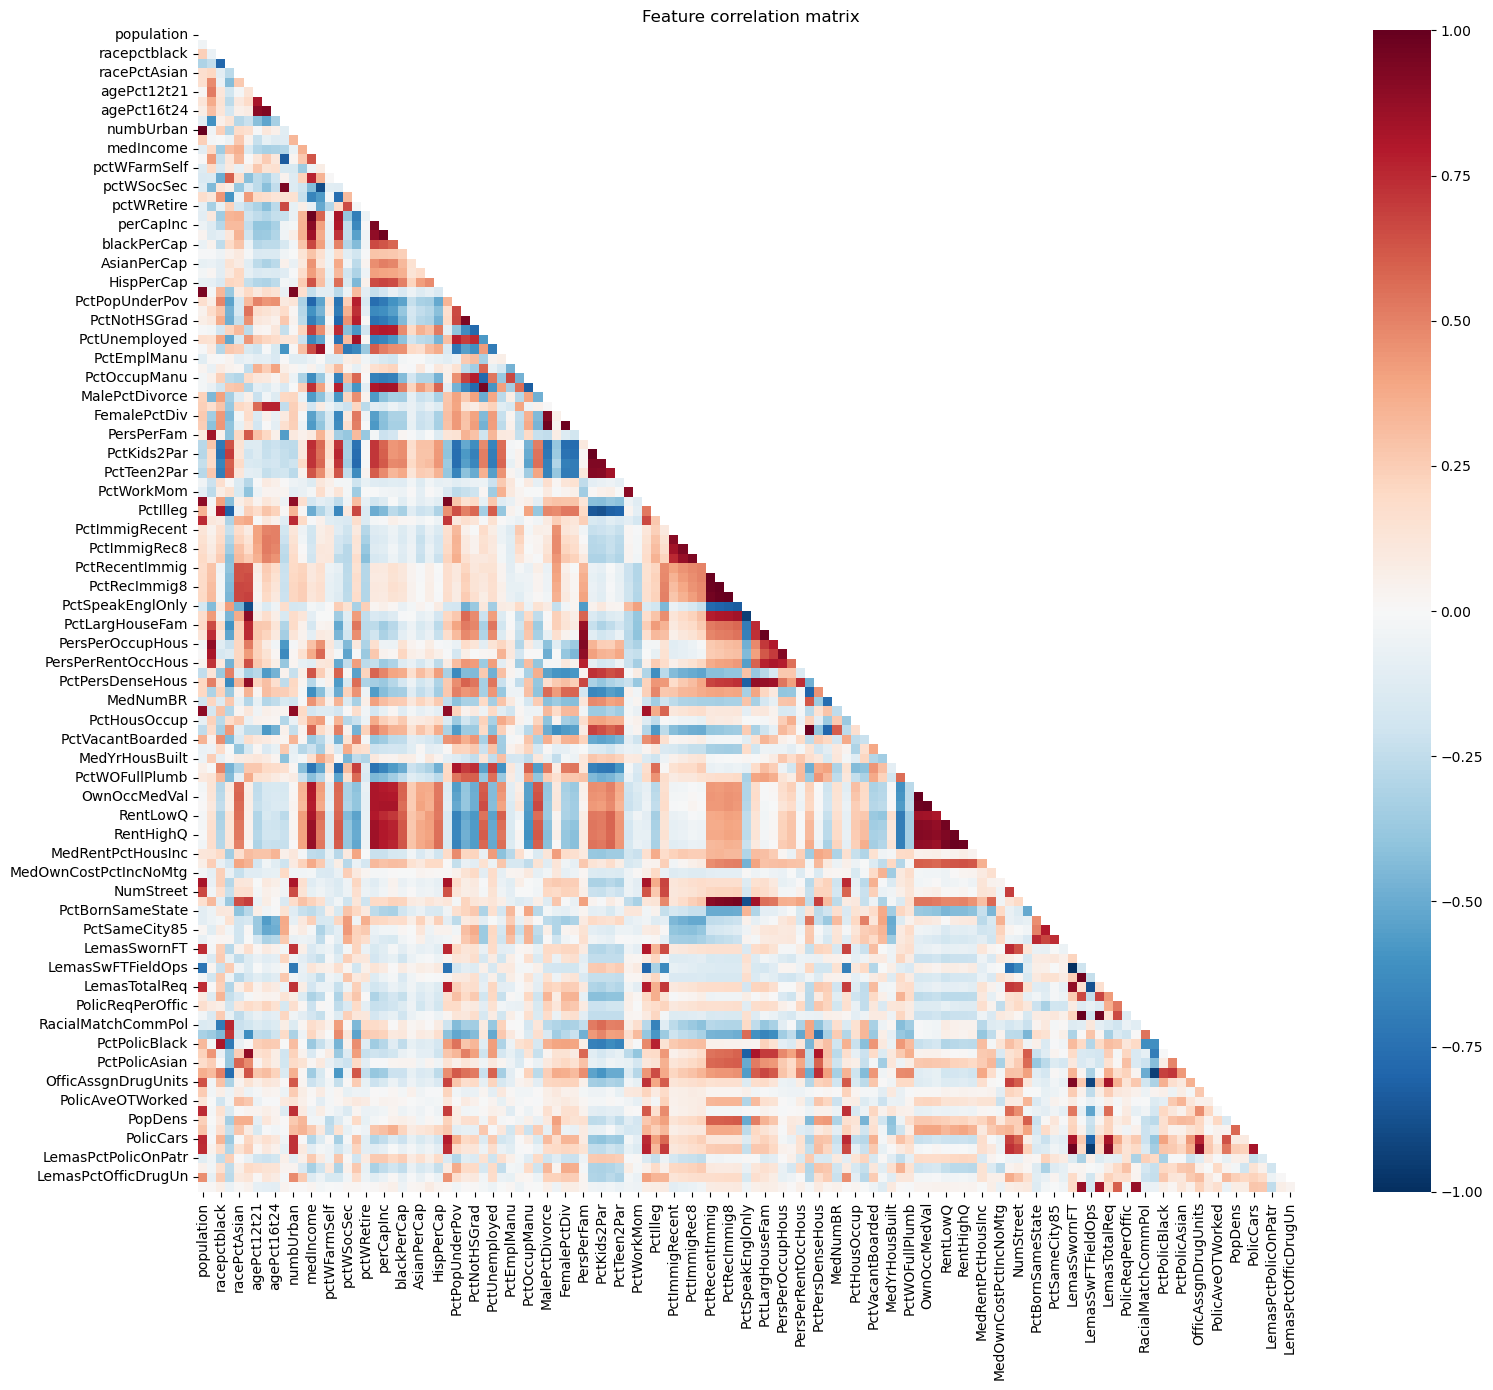

In [12]:
corr = X_train.corr()
# Hide mirroed half and diagonal
upper = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 14))
sns.heatmap(X_train.corr(), mask=upper, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

**d)** Calculate the Coefficient of Variation CV for each feature, where CV=s/m, in which s is sample standard deviation and m is sample mean.

In [13]:
cv = X_train.std() / X_train.mean()
print(cv.sort_values(ascending=False).to_string())

NumStreet                4.292923
NumInShelters            3.470952
NumIlleg                 3.058964
NumImmig                 2.926635
LemasPctOfficDrugUn      2.552946
NumUnderPov              2.342443
population               2.241105
LemasSwornFT             2.051288
numbUrban                2.038461
HousVacant               1.968467
PctPolicAsian            1.821691
PolicOperBudg            1.752336
LandArea                 1.645408
racePctHisp              1.612091
LemasTotalReq            1.610709
PctPolicHisp             1.588205
OfficAssgnDrugUnits      1.536816
PctNotSpeakEnglWell      1.456618
racepctblack             1.428885
PctUsePubTrans           1.397110
racePctAsian             1.359100
PctRecentImmig           1.288287
PctRecImmig5             1.286184
PctRecImmig10            1.270476
PctRecImmig8             1.265579
PctPolicBlack            1.231328
PolicCars                1.199957
PctPersDenseHous         1.132926
PctForeignBorn           1.065880
PctVacantBoard

**e)** Pick $\lfloor\sqrt{128}\rfloor$ features with highest CV, and make scatter plots and box plots for them. Can you draw conclusions about significance of those features, just by the scatter plots?

The ViolentCrimesPerPop was plotted alongside $\lfloor\sqrt{128}\rfloor$ features:

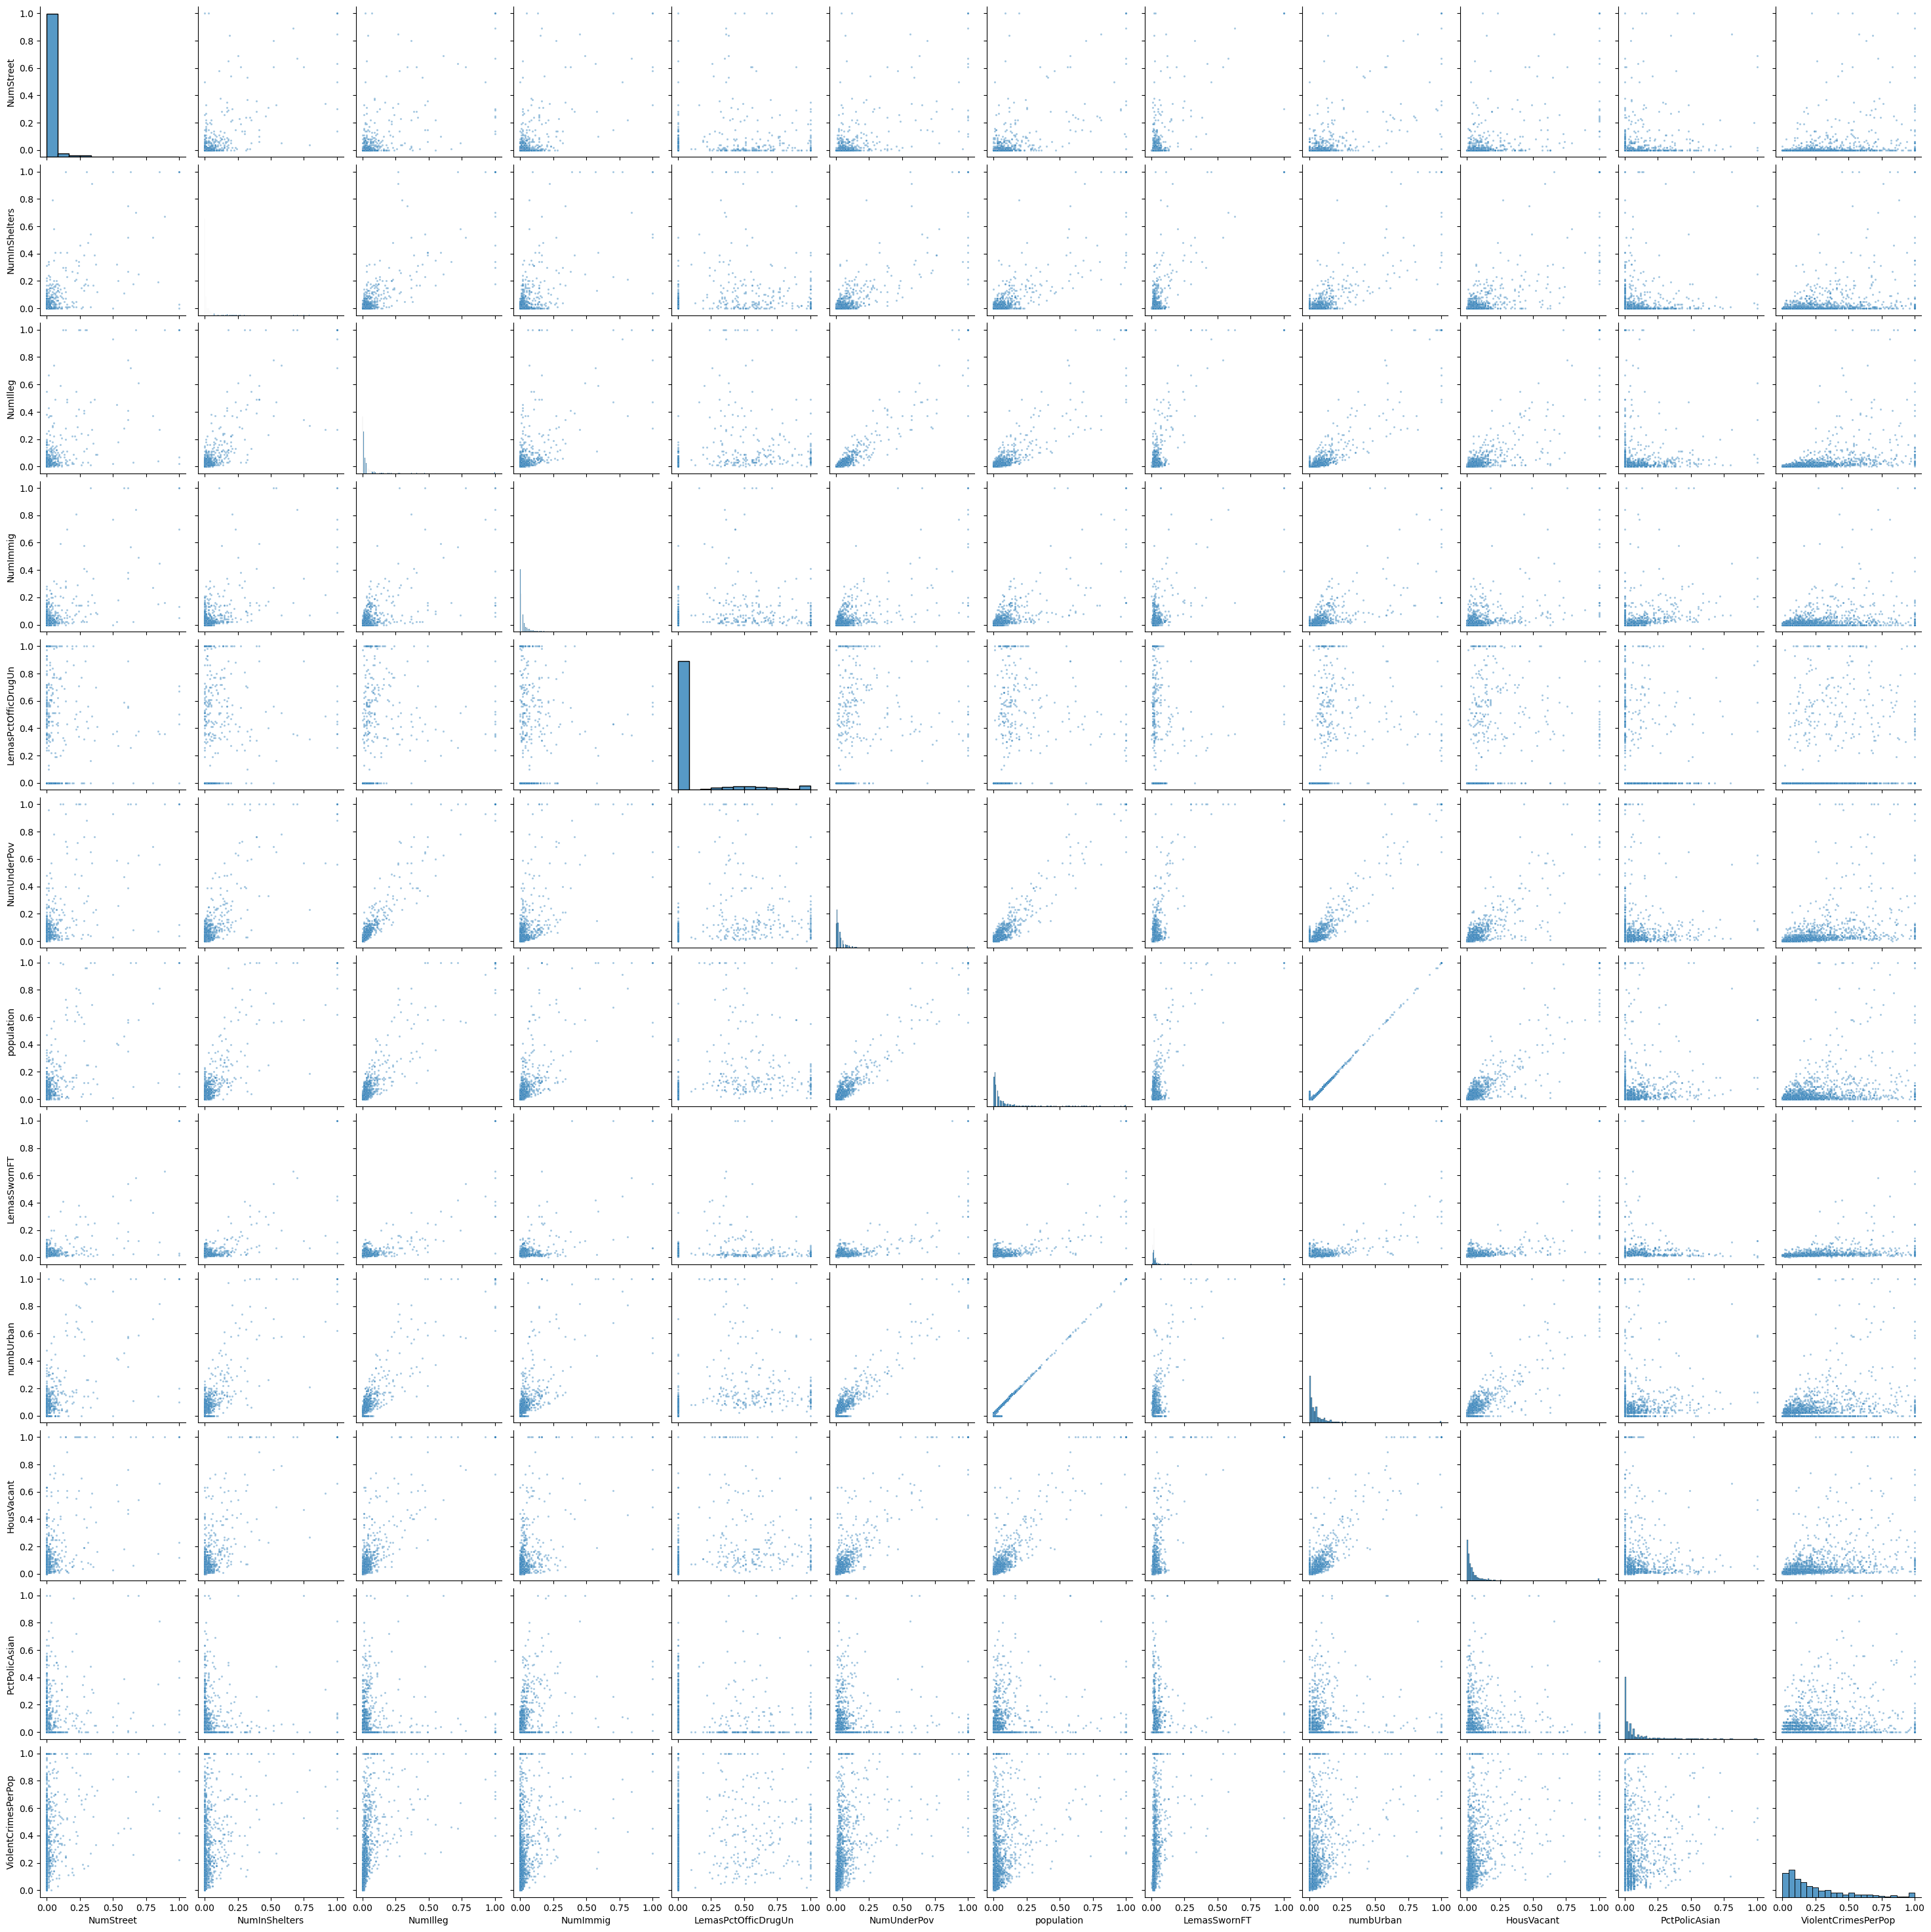

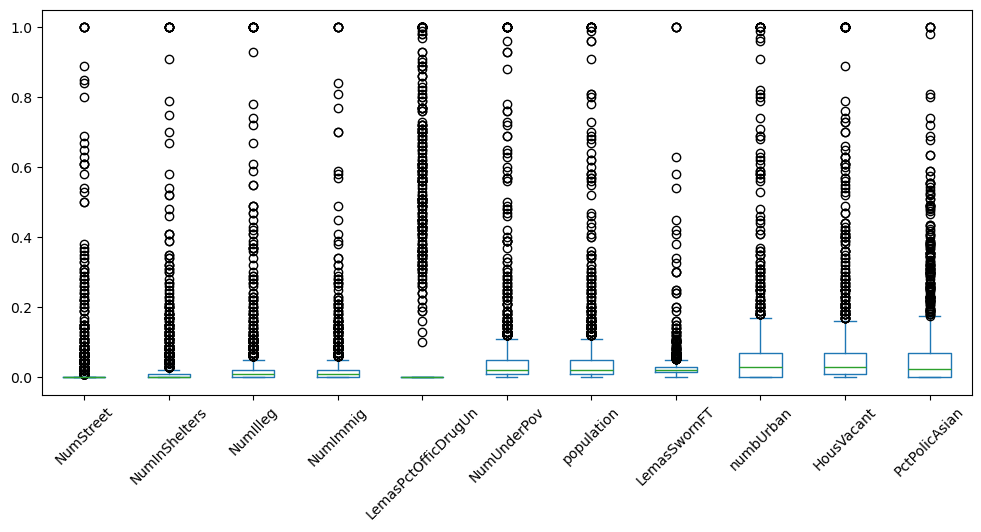

In [14]:
k = int(np.sqrt(128))
top = cv.sort_values(ascending=False).index[:k]

# Scatter plots
sns.pairplot(pd.concat([X_train[top],y_train],axis=1),plot_kws={"s":5,"alpha":0.4})

# Box plots
X_train[top].plot(kind="box",figsize=(12,5),rot=45)
plt.show()


No, you cannot draw conclusions about the significance of these features from the scatter plots. Hypothesis tests are required to determine significance. Also, a feature that looks related to crime might be due to another feature it's correlated with. A high CV measures how much a feature varies relative to its mean, not how much it relates to the target.

It is worth noting that some features are strongly correlated (ex. population and numbUrban, which show an almost perfect straight diagonal line). This indicates unstable individual coefficients.

***

**f)** Fit a linear model using least squares to the training set and report the test error.

In [15]:
lr = LinearRegression()
lr.fit(X_train, y_train)

test_mse = mean_squared_error(y_test, lr.predict(X_test))
print("Test MSE:", test_mse)
print("Test RMSE:", np.sqrt(test_mse))

Test MSE: 0.017538735923882998
Test RMSE: 0.13243389265547925


The test MSE is 0.0175 and the test RMSE is 0.1324.

***

**g)** Fit a ridge regression model on the training set, with λ chosen by cross-validation. Report the test error obtained.

100 λ's were chosen between $10^{-4}$ and $10^{4}$. `RidgeCV` was implemented from sklearn:

In [16]:
kf = KFold(10, shuffle=True, random_state=42)

# Choose scoring by the MSE
ridge = RidgeCV(alphas=np.logspace(-4, 4, 100), cv=kf, scoring="neg_mean_squared_error")
ridge.fit(X_train, y_train)

print("Best λ:", ridge.alpha_)
print("Ridge test MSE:", mean_squared_error(y_test, ridge.predict(X_test)))

Best λ: 3.351602650938848
Ridge test MSE: 0.017311434700834613


The test MSE is 0.0173 with a λ of 3.352.

***

**h)** Fit a LASSO model on the training set, with λ chosen by cross-validation. Report the test error obtained, along with a list of the variables selected by the model. Repeat with standardized 4 features (in this data set, features are already normalized). Report the test error for both cases and compare them.

LASSO's default in sklearn is spacing 100 values on a log scale from the smallest λ at which every coefficient is exactly 0 to 1/1000 of it (eps=1e-3):

In [17]:
lasso = LassoCV(cv=kf, max_iter=50000, random_state=42)
lasso.fit(X_train, y_train)

selected = X_train.columns[lasso.coef_ != 0]
print("Best λ:", lasso.alpha_)
print("LASSO test MSE:", mean_squared_error(y_test, lasso.predict(X_test)))
print(len(selected), "variables selected:")
print(list(selected))

Best λ: 0.00012454087437758504
LASSO test MSE: 0.017535632418024357
71 variables selected:
['racepctblack', 'racePctAsian', 'racePctHisp', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctEmplProfServ', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelte

Using LASSO with standardized features:

In [18]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

lasso_std = LassoCV(cv=kf, max_iter=50000, random_state=42)
lasso_std.fit(X_train_std, y_train)

selected_std = X_train.columns[lasso_std.coef_ != 0]
print("Best λ:", lasso_std.alpha_)
print("Standardized LASSO test MSE:", mean_squared_error(y_test, lasso_std.predict(X_test_std)))
print(len(selected_std), "variables selected:")
print(list(selected_std))

Best λ: 0.0030805808064029053
Standardized LASSO test MSE: 0.01742449138771055
30 variables selected:
['racepctblack', 'agePct12t29', 'pctUrban', 'pctWInvInc', 'pctWPubAsst', 'pctWRetire', 'indianPerCap', 'AsianPerCap', 'MalePctDivorce', 'PctKids2Par', 'PctYoungKids2Par', 'PctWorkMom', 'PctIlleg', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedRentPctHousInc', 'MedOwnCostPctIncNoMtg', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'PolicReqPerOffic', 'RacialMatchCommPol', 'PctPolicBlack', 'PctPolicAsian', 'PolicAveOTWorked', 'PolicBudgPerPop']


The MSE for LASSO is 0.0175. After standardization, the MSE for LASSO is slightly lower at 0.0174 and the number of variables selected goes from 71 to 30 after standardization. Initially, a feature with a small standard deviation would need a bigger coefficient to have the same effect as a feature with a larger standard deviation. Any feature with a larger standard deviation is penalized less in the raw fit, but standardization gives every feature the same standard deviation of 1, so they are penalized on equal terms. LASSO after standardization will drop coefficients not because of scale, but because of usefuleness. 

***

**i)** Fit a PCR model on the training set, with M (the number of principal components) chosen by cross-validation. Report the test error obtained.

In [19]:
pca = PCA()
Z_train = pca.fit_transform(X_train_std)
Z_test = pca.transform(X_test_std)

cv_mse = []
# Test m components, from 1 up to the number of features
for m in range(1, Z_train.shape[1] + 1):
    # Keep the first m components, choose scoring by the MSE
    scores = cross_val_score(LinearRegression(), Z_train[:, :m], y_train,
                             cv=kf, scoring="neg_mean_squared_error")
    cv_mse.append(-scores.mean())

best_m = int(np.argmin(cv_mse)) + 1
pcr = LinearRegression().fit(Z_train[:, :best_m], y_train)

print("Best M:", best_m)
print("PCR test MSE:", mean_squared_error(y_test, pcr.predict(Z_test[:, :best_m])))

Best M: 43
PCR test MSE: 0.018122414770111034


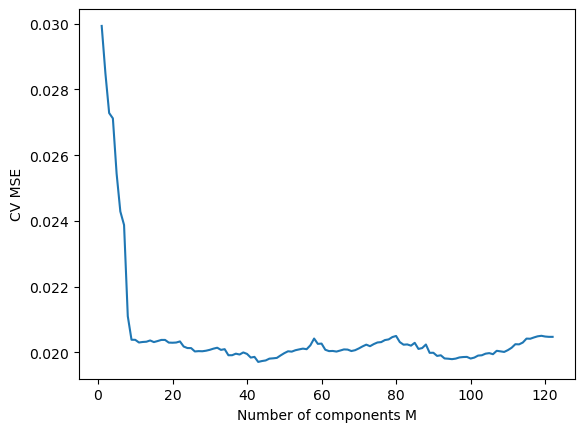

In [20]:
plt.plot(range(1, len(cv_mse) + 1), cv_mse)
plt.xlabel("Number of components M"); plt.ylabel("CV MSE")
plt.show()

Cross-validation selects M=43 components with a test MSE of 0.0181, although the CV curve is almost flat from about 10 components onwards. One could argue for 10 components instead of 43.

***

**j)** In this section, we would like to fit a boosting tree to the data. As in classification trees, one can use any type of regression at each node to build a multivariate regression tree. Because the number of variables is large in this problem, one can use L1-penalized regression at each node. Such a tree is called L1 penalized gradient boosting tree. You can use XGBoost to fit the model tree. Determine α (the regularization term) using cross-validation.

In [21]:
alphas = [0, 0.001, 0.01, 0.1, 1, 10]
cv_mse = []

for a in alphas:

    model = XGBRegressor(
        n_estimators=300,      # Number of gradient boosted trees
        learning_rate=0.05,     # Boosting learning rate, shrinkage parameter
        max_depth=3,            # Maximum tree depth
        reg_alpha=a, 
        random_state=42)
    
    scores = cross_val_score(model, X_train, y_train, cv=kf,
                             scoring="neg_mean_squared_error", n_jobs=1)
    cv_mse.append(-scores.mean())
    print(f"α = {a:<6} CV MSE = {-scores.mean():.5f}")

best_alpha = alphas[int(np.argmin(cv_mse))]

final = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                     reg_alpha=best_alpha, random_state=42)
final.fit(X_train, y_train)

print("Best α:", best_alpha)
print("Boosting test MSE:", mean_squared_error(y_test, final.predict(X_test)))

α = 0      CV MSE = 0.01996
α = 0.001  CV MSE = 0.01995
α = 0.01   CV MSE = 0.02002
α = 0.1    CV MSE = 0.01977
α = 1      CV MSE = 0.01980
α = 10     CV MSE = 0.02144
Best α: 0.1
Boosting test MSE: 0.01674423371971842


Cross-validation yields an α of 0.1 (300 trees, learning rate 0.05, depth 3) with a test MSE of 0.0167. This is slightly lower than least squares, ridge, LASSO, and PCR, meaning that most of the predictable signal in the data is roughly linear, and nonlinear effects add at most a small gain.

***

**References and Citations**

[1] [Acute Inflammations Dataset](https://archive.ics.uci.edu/dataset/184/acute+inflammations)

[2] Decision Tree Classification

* [Simplifying Decision Tree Interpretability with Python & Scikit-learn](https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html)
* [Scikit Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
* [Cost-complexity Pruning](https://www.geeksforgeeks.org/machine-learning/pruning-decision-trees/)

[3] [Communities and Crime Dataset](https://archive.ics.uci.edu/dataset/183/communities+and+crime)

[4] [KNN Imputer](https://www.geeksforgeeks.org/machine-learning/python-imputation-using-the-knnimputer/)

[5] Regression
* [RidgeCV](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeCV.html)
* [LassoCV](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html)

[6] XGBoost
* [Python API](https://xgboost.readthedocs.io/en/latest/python/python_api.html)
* [CodeStudy](https://www.codestudy.net/blog/xgboost-sklearn/)
